# 02 · Stylometry evaluation

**Question.** Does S-Way's chunk-standardised stylometric comparison put same-author text pairs closer than different-author pairs, how does that depend on text length, and what agreement thresholds should the *Moderate*/*High* labels use?

**Data.** Prose by Austen (3 novels), Chesterton (3), Melville, Carroll, Edgeworth, Burgess and Bryant from Project Gutenberg. Pairs are drawn from **different books** where possible so that plot vocabulary does not leak.

**Confounds.** Same-author pairs here also share era and genre; real-world comparisons (e.g. students in one class answering one question) are harder. Results are an upper bound.

In [1]:
import sys, json, random, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
%matplotlib inline
sys.path.insert(0, '.')
from sway_research import *
RESULTS = DATA / 'results'; RESULTS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 90, 'font.family': 'monospace', 'axes.facecolor': '#EDE3CC', 'figure.facecolor': '#F4ECD9'})
pd.set_option('display.width', 140)

In [2]:
rng = random.Random(7)
prose = ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'chesterton-ball.txt', 'chesterton-brown.txt',
         'chesterton-thursday.txt', 'melville-moby_dick.txt', 'carroll-alice.txt', 'edgeworth-parents.txt', 'burgess-busterbrown.txt', 'bryant-stories.txt']
words = {b: re.sub(r'\s+', ' ', load_book(b)).split(' ') for b in prose}
def chunk(b, n):
    w = words[b]; i = rng.randrange(1000, len(w) - n - 1); return ' '.join(w[i:i + n])
import re
pairs = []
for n in [300, 1000, 2500]:
    for _ in range(45):
        a = rng.choice([b for b in prose if author_of(b) in ('austen', 'chesterton')])
        others = [b for b in prose if author_of(b) == author_of(a) and b != a]
        pairs.append(dict(n=n, same=1, a=chunk(a, n), b=chunk(rng.choice(others), n), pa=a))
    for _ in range(45):
        a, b = rng.sample(prose, 2)
        while author_of(a) == author_of(b):
            a, b = rng.sample(prose, 2)
        pairs.append(dict(n=n, same=0, a=chunk(a, n), b=chunk(b, n), pa=a))
res = run_js([{'op': 'style', 'a': p['a'], 'b': p['b']} for p in pairs])
df = pd.DataFrame([dict(n=p['n'], same=p['same'], **{k: r[k] for k in ['agreement', 'disagreement', 'cosine', 'distance']}) for p, r in zip(pairs, res)])
df.groupby(['n', 'same'])[['agreement', 'disagreement', 'cosine']].mean().round(3)

agreement  disagreement  cosine
n    same                                 
300  0         0.476         0.179   0.901
     1         0.536         0.152   0.919
1000 0         0.480         0.143   0.914
     1         0.554         0.088   0.971
2500 0         0.423         0.215   0.987
     1         0.555         0.085   0.990

In [3]:
tab = []
for n, g in df.groupby('n'):
    pos, neg = g[g.same == 1], g[g.same == 0]
    tab.append(dict(words=n, auc_agreement=roc_auc(pos.agreement, neg.agreement), auc_low_disagreement=roc_auc(-pos.disagreement, -neg.disagreement), auc_cosine=roc_auc(pos.cosine, neg.cosine)))
pd.DataFrame(tab).round(3)

,words,auc_agreement,auc_low_disagreement,auc_cosine
0,300,0.627,0.603,0.657
1,1000,0.729,0.768,0.609
2,2500,0.899,0.944,0.635


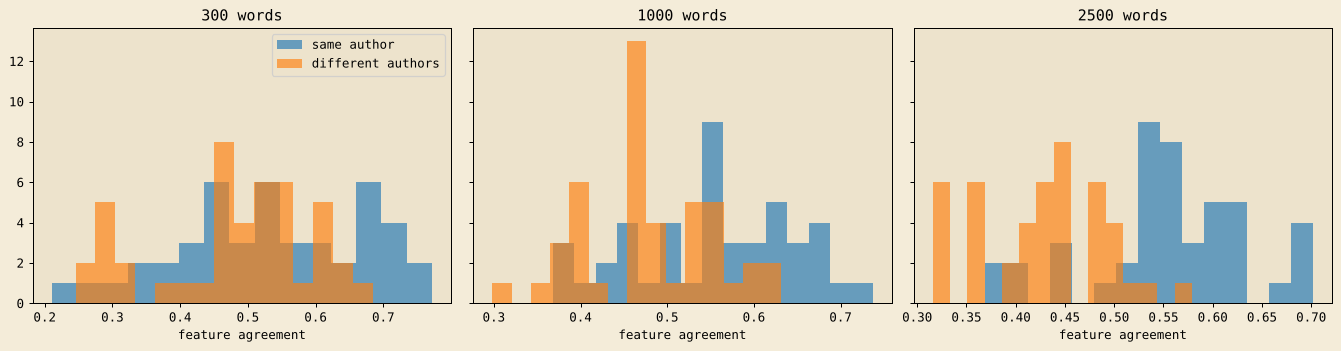

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for a, (n, g) in zip(ax, df.groupby('n')):
    a.hist(g[g.same == 1].agreement, bins=15, alpha=.65, label='same author'); a.hist(g[g.same == 0].agreement, bins=15, alpha=.65, label='different authors')
    a.set_title(f'{n} words'); a.set_xlabel('feature agreement')
ax[0].legend(); plt.tight_layout(); plt.show()

## Thresholds

Choose, on texts of 1,000+ words, the agreement / disagreement limits at which a *High* label has ≥ 90 % precision for same-author pairs and *Moderate* ≥ 70 %. The 300-word results show why S-Way marks short texts as insufficient.

In [5]:
long = df[df.n >= 1000]
def prec_rec(d, ag, dis):
    sel = (d.agreement >= ag) & (d.disagreement <= dis)
    if sel.sum() == 0: return 0, 0, 0
    return d[sel].same.mean(), sel[d.same == 1].mean(), sel.sum()
grid = []
for ag in np.arange(0.4, 0.95, 0.05):
    for dis in [0.04, 0.06, 0.08, 0.1, 0.15, 0.2, 0.25]:
        pr, rc, k = prec_rec(long, ag, dis); grid.append(dict(ag=round(ag, 2), dis=dis, precision=pr, recall=rc, selected=k))
grid = pd.DataFrame(grid)
hi = grid[(grid.precision >= 0.9) & (grid.selected >= 5)].sort_values('recall', ascending=False).head(1)
mo = grid[(grid.precision >= 0.7) & (grid.selected >= 5)].sort_values('recall', ascending=False).head(1)
pd.concat([hi.assign(label='High'), mo.assign(label='Moderate')])

,ag,dis,precision,recall,selected,label
17,0.5,0.10,0.934426,0.633333,61,High
4,0.4,0.15,0.702703,0.866667,111,Moderate


In [6]:
H = hi.iloc[0] if len(hi) else pd.Series(dict(ag=0.75, dis=0.08)); M = mo.iloc[0] if len(mo) else pd.Series(dict(ag=0.5, dis=0.2))
from sklearn.metrics import confusion_matrix
yhat = ((long.agreement >= M.ag) & (long.disagreement <= M.dis)).astype(int)
print('Moderate-or-higher vs same author, texts ≥1000 words  [[TN FP] [FN TP]]'); print(confusion_matrix(long.same, yhat))

Moderate-or-higher vs same author, texts ≥1000 words  [[TN FP] [FN TP]]
[[57 33]
 [12 78]]


## Optional supervised attribution and clustering (scikit-learn)

With properly labelled data a supervised model can learn which features matter. Here a logistic regression attributes 1,000-word chunks to authors, evaluated with **GroupKFold by book** so the test book is never seen in training. Agglomerative clustering is compared with the author labels. These experiments inform research only; the app ships the unsupervised, explainable comparison.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score
multi = [b for b in prose if author_of(b) in ('austen', 'chesterton')] + ['melville-moby_dick.txt', 'edgeworth-parents.txt']
X, y, g = [], [], []
feats = run_js([{'op': 'styleFeatures', 'text': chunk(b, 1000)} for b in multi for _ in range(12)])
i = 0
for b in multi:
    for _ in range(12):
        X.append(list(feats[i].values())); y.append(author_of(b)); g.append(b); i += 1
X = np.array(X)
mask = np.isin(y, ['austen', 'chesterton'])
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
scores = cross_val_score(clf, X[mask], np.array(y)[mask], groups=np.array(g)[mask], cv=GroupKFold(n_splits=3))
print('Austen vs Chesterton, unseen-book accuracy per fold:', scores.round(3))
labels = AgglomerativeClustering(n_clusters=4).fit_predict(StandardScaler().fit_transform(X))
print('Agglomerative clustering vs authors, adjusted Rand index:', round(adjusted_rand_score(y, labels), 3))

Austen vs Chesterton, unseen-book accuracy per fold: [1.    1.    0.917]
Agglomerative clustering vs authors, adjusted Rand index: 0.668


In [8]:
out = {'style_fusion': {'highAgreement': float(H.ag), 'highMaxDisagreement': float(H.dis), 'modAgreement': float(M.ag), 'modMaxDisagreement': float(M.dis)},
       'metrics': {'auc_by_length': tab, 'attribution_accuracy_unseen_book': scores.tolist()}}
(RESULTS / 'style.json').write_text(json.dumps(out, indent=2, default=float)); out

{'style_fusion': {'highAgreement': 0.5,
  'highMaxDisagreement': 0.1,
  'modAgreement': 0.4,
  'modMaxDisagreement': 0.15},
 'metrics': {'auc_by_length': [{'words': 300,
    'auc_agreement': 0.6269135802469136,
    'auc_low_disagreement': 0.6034567901234568,
    'auc_cosine': 0.6565432098765431},
   {'words': 1000,
    'auc_agreement': 0.7293827160493827,
    'auc_low_disagreement': 0.768395061728395,
    'auc_cosine': 0.608641975308642},
   {'words': 2500,
    'auc_agreement': 0.8990123456790123,
    'auc_low_disagreement': 0.9437037037037037,
    'auc_cosine': 0.6348148148148148}],
  'attribution_accuracy_unseen_book': [1.0, 1.0, 0.9166666666666666]}}